In [6]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
%matplotlib inline

In [7]:
# Change parameters and the name of the output folder
param_1 = 'Match proportion'
param_2 = 'Match count'
output_folder = 'output-data-extracted/OUTPUT_MP_MC_extracted'

In [8]:
# Change parameters and the name of the output folder
param_1 = 'Match proportion'
param_2 = 'Trim quality'
output_folder = 'output-data-extracted/OUTPUT_MP_TQ_extracted'

In [9]:
# Change parameters and the name of the output folder
param_1 = 'Trim quality'
param_2 = 'Trim window'
output_folder = 'output-data-extracted/OUTPUT_TQ_TW_extracted'

In [10]:
parameters_df = pd.read_csv(f'{output_folder}/parameters.csv').drop_duplicates().set_index('Directory name')
parameters_df.head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW6-OUTPUT,0.8,25,9,6
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW8-OUTPUT,0.8,25,9,8
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW10-OUTPUT,0.8,25,9,10
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW12-OUTPUT,0.8,25,9,12


In [11]:
output_dirs = []
for dir in parameters_df.index:
    output_dirs.append(dir)
output_dirs

['Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ9_TW6-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ9_TW8-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ9_TW10-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ9_TW12-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ10_TW4-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ10_TW6-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ10_TW8-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ10_TW10-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ10_TW12-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ11_TW4-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ11_TW6-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ11_TW8-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ11_TW10-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ11_TW12-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ12_TW4-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ12_TW6-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ12_TW8-OUTPUT',
 'Longitudinal_Sample6_MP0.8_MC25_TQ12_TW10-OUTPUT',
 'Longitud

In [12]:
merged_info_dfs = []
for dir in output_dirs:
    merged_info_dfs.append(pd.read_csv(f'{output_folder}/{dir}/merged.info', sep='\t'))
    merged_info_dfs[-1]['Directory name'] = dir
merged_info_dfs[0].head()

,sample,usedEntries,totalEntries,Directory name
0,fish4_s6_rep1,2404,7143,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT
1,fish5_s6_rep1,29510,39848,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT
2,fish6_s6_rep1,17929,25842,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT
3,fish8_s6_rep1,67408,75786,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT
4,fish9_s6_rep1,28957,40527,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT


In [13]:
results_df = pd.concat(merged_info_dfs)
print(results_df.info())
for col in parameters_df.columns:
    results_df[col] = results_df['Directory name'].map(parameters_df[col])
results_df['usedEntriesProportion'] = results_df['usedEntries'].astype('float64') / results_df['totalEntries']
results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 245 entries, 0 to 6
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   sample          245 non-null    object
 1   usedEntries     245 non-null    int64 
 2   totalEntries    245 non-null    int64 
 3   Directory name  245 non-null    object
dtypes: int64(2), object(2)
memory usage: 9.6+ KB
None


,sample,usedEntries,totalEntries,Directory name,Match proportion,Match count,Trim quality,Trim window,usedEntriesProportion
0,fish4_s6_rep1,2404,7143,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4,0.336553
1,fish5_s6_rep1,29510,39848,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4,0.740564
2,fish6_s6_rep1,17929,25842,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4,0.693793
3,fish8_s6_rep1,67408,75786,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4,0.889452
4,fish9_s6_rep1,28957,40527,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4,0.714511


In [14]:
mean_results_df = results_df.groupby([param_1, param_2]).agg({
    'usedEntriesProportion': 'mean',
})
mean_results_df.tail(20)

usedEntriesProportion
Trim quality Trim window                       
12           4                         0.722535
             6                         0.722530
             8                         0.722542
             10                        0.722533
             12                        0.722533
13           4                         0.753997
             6                         0.733938
             8                         0.726494
             10                        0.724204
             12                        0.723309
14           4                         0.779195
             6                         0.751423
             8                         0.736802
             10                        0.730187
             12                        0.726724
15           4                         0.887950
             6                         0.824093
             8                         0.779503
             10                        0.756019
             12                        0.743274

The heatmap shows the mean proportion of used entries for each parameter combo.

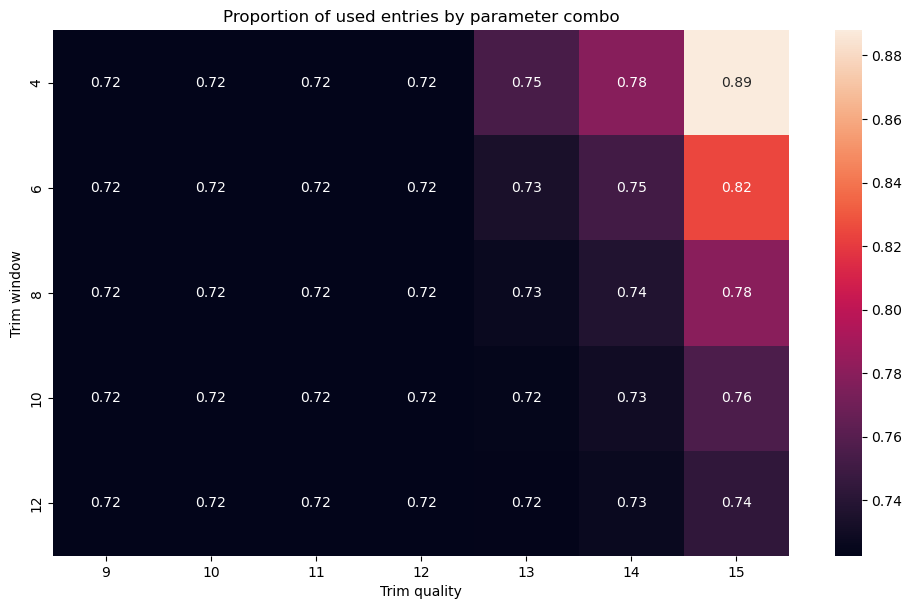

In [15]:
fig, ax = plt.subplots(figsize=(10,6))
pivot_data = mean_results_df.reset_index().pivot(index=param_2, columns=param_1, values='usedEntriesProportion')
sb.heatmap(pivot_data, annot=True, ax=ax, square=True)
plt.title('Proportion of used entries by parameter combo')
plt.tight_layout()
plt.show()

Lineplots show how the proportion of used entries for each sample changes depending on the paramaters chosen.

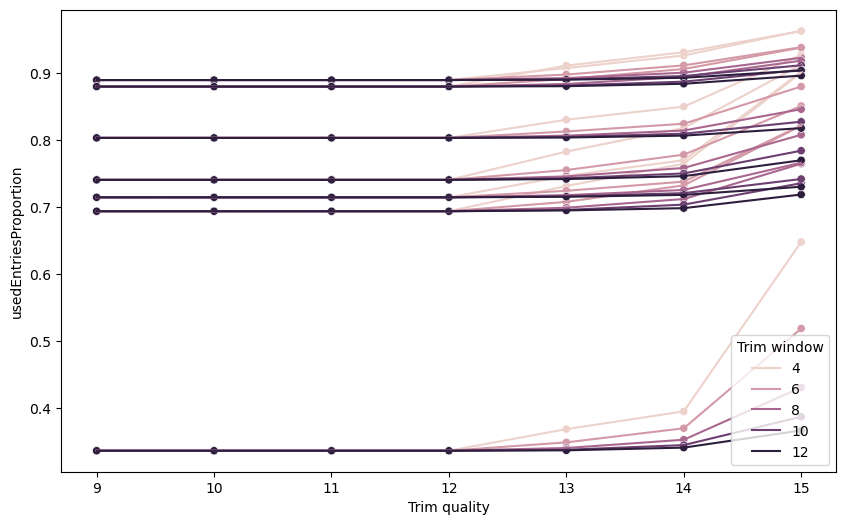

In [16]:
fig, ax = plt.subplots(figsize=(10,6))
sb.scatterplot(data=results_df, x=param_1, y='usedEntriesProportion', ax=ax, hue=param_2, legend=False)
sb.lineplot(data=results_df, x=param_1, y='usedEntriesProportion', hue=param_2, estimator=None, units='sample', ax=ax)
plt.show()

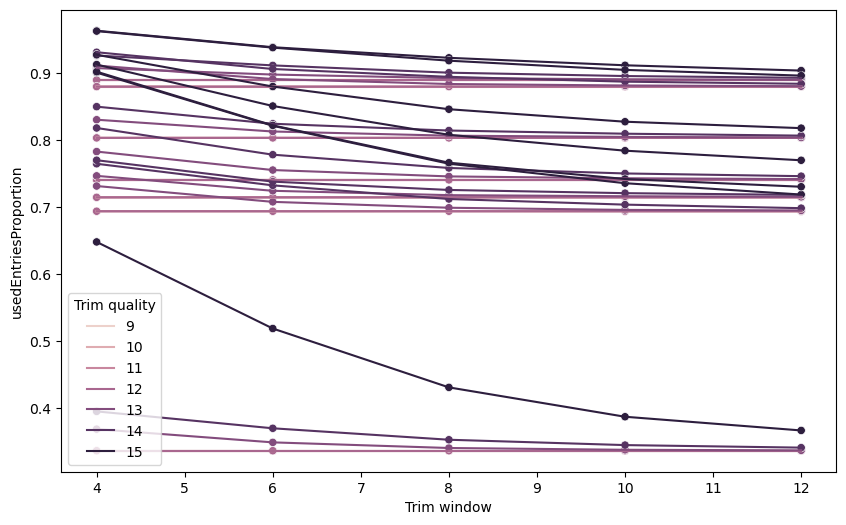

In [17]:
fig, ax = plt.subplots(figsize=(10,6))
sb.scatterplot(data=results_df, x=param_2, y='usedEntriesProportion', ax=ax, hue=param_1, legend=False)
sb.lineplot(data=results_df, x=param_2, y='usedEntriesProportion', hue=param_1, estimator=None, units='sample', ax=ax)
plt.show()